In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Level A

### 1.1 A1. Data types & Attributes 

In [2]:
df = pd.read_csv("./datasets/ramen-ratings.csv")

In [3]:
print("INFORMATION OF DataSet\n")
df.info()
print("\nDataTypes\n")
print(df.dtypes)

INFORMATION OF DataSet

<class 'pandas.DataFrame'>
RangeIndex: 2580 entries, 0 to 2579
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Review #  2580 non-null   int64
 1   Brand     2580 non-null   str  
 2   Variety   2580 non-null   str  
 3   Style     2578 non-null   str  
 4   Country   2580 non-null   str  
 5   Stars     2580 non-null   str  
 6   Top Ten   41 non-null     str  
dtypes: int64(1), str(6)
memory usage: 141.2 KB

DataTypes

Review #    int64
Brand         str
Variety       str
Style         str
Country       str
Stars         str
Top Ten       str
dtype: object


In [4]:
df.head(10)

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
0,2580,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,NaN
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1,NaN
2,2578,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25,NaN
3,2577,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,NaN
4,2576,Ching's Secret,Singapore Curry,Pack,India,3.75,NaN
5,2575,Samyang Foods,Kimchi song Song Ramen,Pack,South Korea,4.75,NaN
6,2574,Acecook,Spice Deli Tantan Men With Cilantro,Cup,Japan,4,NaN
7,2573,Ikeda Shoku,Nabeyaki Kitsune Udon,Tray,Japan,3.75,NaN
8,2572,Ripe'n'Dry,Hokkaido Soy Sauce Ramen,Pack,Japan,0.25,NaN
9,2571,KOKA,The Original Spicy Stir-Fried Noodles,Pack,Singapore,2.5,NaN


1. Review #: Qualitative data and considered to be the **Nominal**, due to numerical values which represents IDs.
2. Brand: Qulitative data and it's **Nominal**, because it's simply the names of Brands.
3. Variety: Qualitative data and it's also **Nominal**, because it represents different flavours of ramen.
4. Style: Qualitative **Nominal** data, because it represents type of how your ramen will be packed.
5. Country: Qualitative **Nominal** data - simply represents the country.
6. Stars: Quantitative data, which can be either **Continuous**, because it's measures the ramen quality on a scale that includes decimal numbers. But it also might be considered as Qualitative data **Ordinal**, due to its representing the rating of ramen.

In [5]:
print(df["Top Ten"].dropna().head(10))

616     2016 #10
633      2016 #1
655      2016 #8
673      2016 #5
752      2016 #9
891      2016 #7
942     2015 #10
963      2015 #7
995      2015 #4
1059     2015 #9
Name: Top Ten, dtype: str


7. Top Ten: We clearly see that it shows ranking, which means it's Qualitative **Ordinal** data.

### 1.2 A2 Descriptive Statistics

In [6]:
num_cols = df.select_dtypes(include = "number")
print(num_cols)

      Review #
0         2580
1         2579
2         2578
3         2577
4         2576
...        ...
2575         5
2576         4
2577         3
2578         2
2579         1

[2580 rows x 1 columns]


We have only **Review** as a numerical column, because column **Stars** is being treated as an "object" -> We need to convert it into numerical values.

In [7]:
df["Stars"] = pd.to_numeric(df["Stars"] , errors = "coerce")

In [8]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
print(numeric_cols)

Index(['Review #', 'Stars'], dtype='str')


Review # Statistics
Mean: 1290.5000 | Median: 1290.5000 | Mode: 1
Range: 2579.0000 | Variance: 554915.0000 | Std Dev: 744.9262
IQR: 1289.5000 (Q1: 645.75, Q3: 1935.25)
Outlier Count: 0
Unique Outlier Values: []

Stars Statistics
Mean: 3.6547 | Median: 3.7500 | Mode: 4.0
Range: 5.0000 | Variance: 1.0309 | Std Dev: 1.0153
IQR: 1.0000 (Q1: 3.25, Q3: 4.25)
Outlier Count: 129
Unique Outlier Values: [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0, 1.1, 1.25, 1.5]



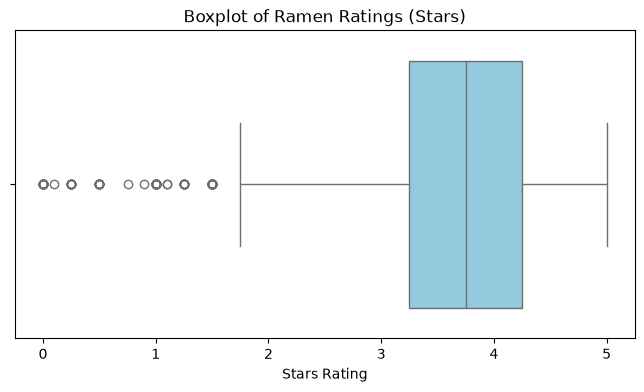

In [9]:
for col in numeric_cols:
    s = df[col].dropna()
    
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode()[0]
    range_val = s.max() - s.min()
    var_val = s.var()
    std_val = s.std()
    
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    
    print(f"{col} Statistics")
    print(f"Mean: {mean_val:.4f} | Median: {median_val:.4f} | Mode: {mode_val}")
    print(f"Range: {range_val:.4f} | Variance: {var_val:.4f} | Std Dev: {std_val:.4f}")
    print(f"IQR: {iqr:.4f} (Q1: {q1}, Q3: {q3})")
    print(f"Outlier Count: {len(outliers)}")
    print(f"Unique Outlier Values: {sorted(outliers.unique().tolist())}\n")

# Boxplot for Stars
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Stars'], color='skyblue')
plt.title('Boxplot of Ramen Ratings (Stars)')
plt.xlabel('Stars Rating')
plt.show()

### 1.3 A3. Handling Missing Data

In [10]:
from sklearn.impute import KNNImputer

In [11]:
# Artificially introduce 5% NaN values using a fixed random seed
np.random.seed(42)
stars_missing = df['Stars'].copy()
mask = np.random.rand(len(stars_missing)) < 0.05
stars_missing[mask] = np.nan

In [12]:
# Method A: Constant Value Imputation (e.g., 0)
df['Stars_const'] = stars_missing.fillna(0.0)

# Method B: Mean / Median / Mode Imputation
df['Stars_mean'] = stars_missing.fillna(stars_missing.mean())
df['Stars_median'] = stars_missing.fillna(stars_missing.median())
df['Stars_mode'] = stars_missing.fillna(stars_missing.mode()[0])

# Method C: Predictive Imputation (KNN with k=5)
knn_data = pd.DataFrame({'Review #': df['Review #'], 'Stars': stars_missing})
imputer = KNNImputer(n_neighbors=5)
df['Stars_knn'] = imputer.fit_transform(knn_data)[:, 1]

In [13]:
comparison_data = {
    'Dataset Version': [
        'Original (Clean)',
        'With 5% Missing (Dropped)',
        'Constant Imputation (0.0)',
        'Mean Imputation',
        'Median Imputation',
        'Mode Imputation',
        'KNN Imputation (k=5)'
    ],
    'Mean': [
        df['Stars'].mean(),
        stars_missing.mean(),
        df['Stars_const'].mean(),
        df['Stars_mean'].mean(),
        df['Stars_median'].mean(),
        df['Stars_mode'].mean(),
        df['Stars_knn'].mean()
    ],
    'Std Deviation': [
        df['Stars'].std(),
        stars_missing.std(),
        df['Stars_const'].std(),
        df['Stars_mean'].std(),
        df['Stars_median'].std(),
        df['Stars_mode'].std(),
        df['Stars_knn'].std()
    ]
}

comparison_df = pd.DataFrame(comparison_data)
print("COMPARISON TABLE")
print(comparison_df.to_string(index=False))

COMPARISON TABLE
          Dataset Version     Mean  Std Deviation
         Original (Clean) 3.654676       1.015331
With 5% Missing (Dropped) 3.650552       1.018437
Constant Imputation (0.0) 3.459535       1.282188
          Mean Imputation 3.650552       0.991423
        Median Imputation 3.655756       0.991670
          Mode Imputation 3.668837       0.994473
     KNN Imputation (k=5) 3.654314       0.998714


In [14]:
imputed_comparison = pd.DataFrame({
    'Review #': df.loc[mask, 'Review #'],
    'Original Stars': df.loc[mask, 'Stars'],
    'Constant (0.0)': df.loc[mask, 'Stars_const'],
    'Mean Fill': df.loc[mask, 'Stars_mean'],
    'Median Fill': df.loc[mask, 'Stars_median'],
    'Mode Fill': df.loc[mask, 'Stars_mode'],
    'KNN Fill': df.loc[mask, 'Stars_knn']
})

print("SAMPLE OF IMPUTED VALUES FOR MISSING ROWS")
print(imputed_comparison.head(10))

SAMPLE OF IMPUTED VALUES FOR MISSING ROWS
     Review #  Original Stars  Constant (0.0)  Mean Fill  Median Fill  \
10       2570            5.00             0.0   3.650552         3.75   
29       2551            4.00             0.0   3.650552         3.75   
42       2538            5.00             0.0   3.650552         3.75   
58       2522            5.00             0.0   3.650552         3.75   
72       2508            3.75             0.0   3.650552         3.75   
98       2482            4.75             0.0   3.650552         3.75   
100      2480            4.25             0.0   3.650552         3.75   
128      2452            5.00             0.0   3.650552         3.75   
145      2435            3.50             0.0   3.650552         3.75   
168      2412            3.25             0.0   3.650552         3.75   

     Mode Fill  KNN Fill  
10         4.0      3.30  
29         4.0      4.55  
42         4.0      4.10  
58         4.0      4.50  
72         4.0     

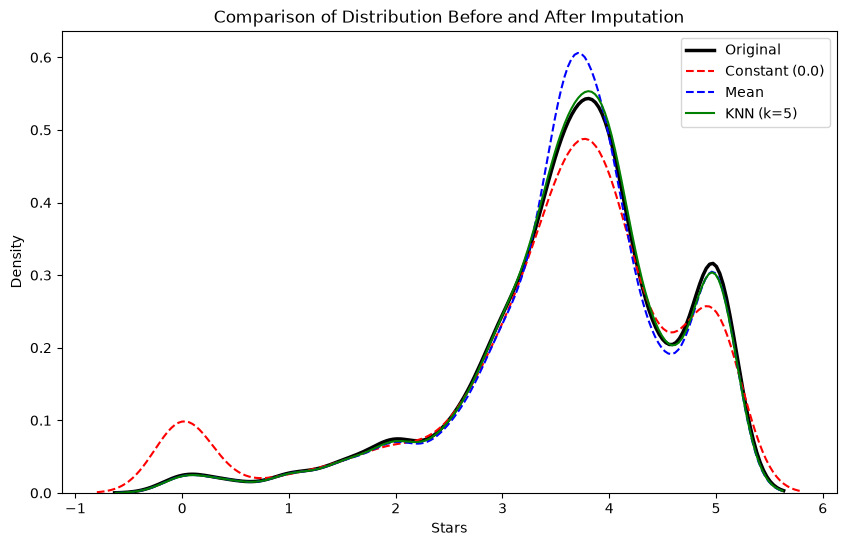

In [15]:
plt.figure(figsize=(10, 6))

sns.kdeplot(df['Stars'], label='Original', color='black', linewidth=2.5)
sns.kdeplot(df['Stars_const'], label='Constant (0.0)', color='red', linestyle='--')
sns.kdeplot(df['Stars_mean'], label='Mean', color='blue', linestyle='--')
sns.kdeplot(df['Stars_knn'], label='KNN (k=5)', color='green', linestyle='-')

plt.title('Comparison of Distribution Before and After Imputation')
plt.xlabel('Stars')
plt.ylabel('Density')
plt.legend()
plt.show()

For constant imputation, filling the missing values with 0.0 was super easy and fast to code. However, it completely ruined our data averages. The original mean was 3.6547, but putting zeros brought it all the way down to 3.459535. It also blew up the standard deviation from 1.0153 to 1.282188 because zero is nowhere near the typical ratings.

Using mean imputation kept our average at 3.6514, which matched the dataset before filling in the blanks. The problem is that repeating the same average number 132 times squeezed our standard deviation down to 0.9874. Median and mode did almost the same thing by shifting the averages slightly higher to 3.6565 and 3.6693 while still shrinking the standard deviation. These simple methods are quick, but they completely ignore how other columns relate to each other.

KNN imputation gave us the most realistic numbers overall. It was a bit trickier to set up and took more computer effort since it had to calculate distances between rows. But because it used patterns from neighboring entries, its standard deviation came out to 0.9961. This was the closest we got to the original standard deviation of 1.0153 without pulling down the mean.

# Level B

### 2.1 B1. Normalization & Standardization

In [16]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df = pd.read_csv('./datasets/WineQT.csv')

In [17]:
summary = pd.DataFrame(
    {
        'Min': df.min(),
        'Max': df.max(),
        'Mean': df.mean(),
        'Std Dev': df.std(),
    }
)
print(summary)

                          Min         Max        Mean     Std Dev
fixed acidity         4.60000    15.90000    8.311111    1.747595
volatile acidity      0.12000     1.58000    0.531339    0.179633
citric acid           0.00000     1.00000    0.268364    0.196686
residual sugar        0.90000    15.50000    2.532152    1.355917
chlorides             0.01200     0.61100    0.086933    0.047267
free sulfur dioxide   1.00000    68.00000   15.615486   10.250486
total sulfur dioxide  6.00000   289.00000   45.914698   32.782130
density               0.99007     1.00369    0.996730    0.001925
pH                    2.74000     4.01000    3.311015    0.156664
sulphates             0.33000     2.00000    0.657708    0.170399
alcohol               8.40000    14.90000   10.442111    1.082196
quality               3.00000     8.00000    5.657043    0.805824
Id                    0.00000  1597.00000  804.969379  463.997116


In [18]:
features = ["total sulfur dioxide", "pH"]

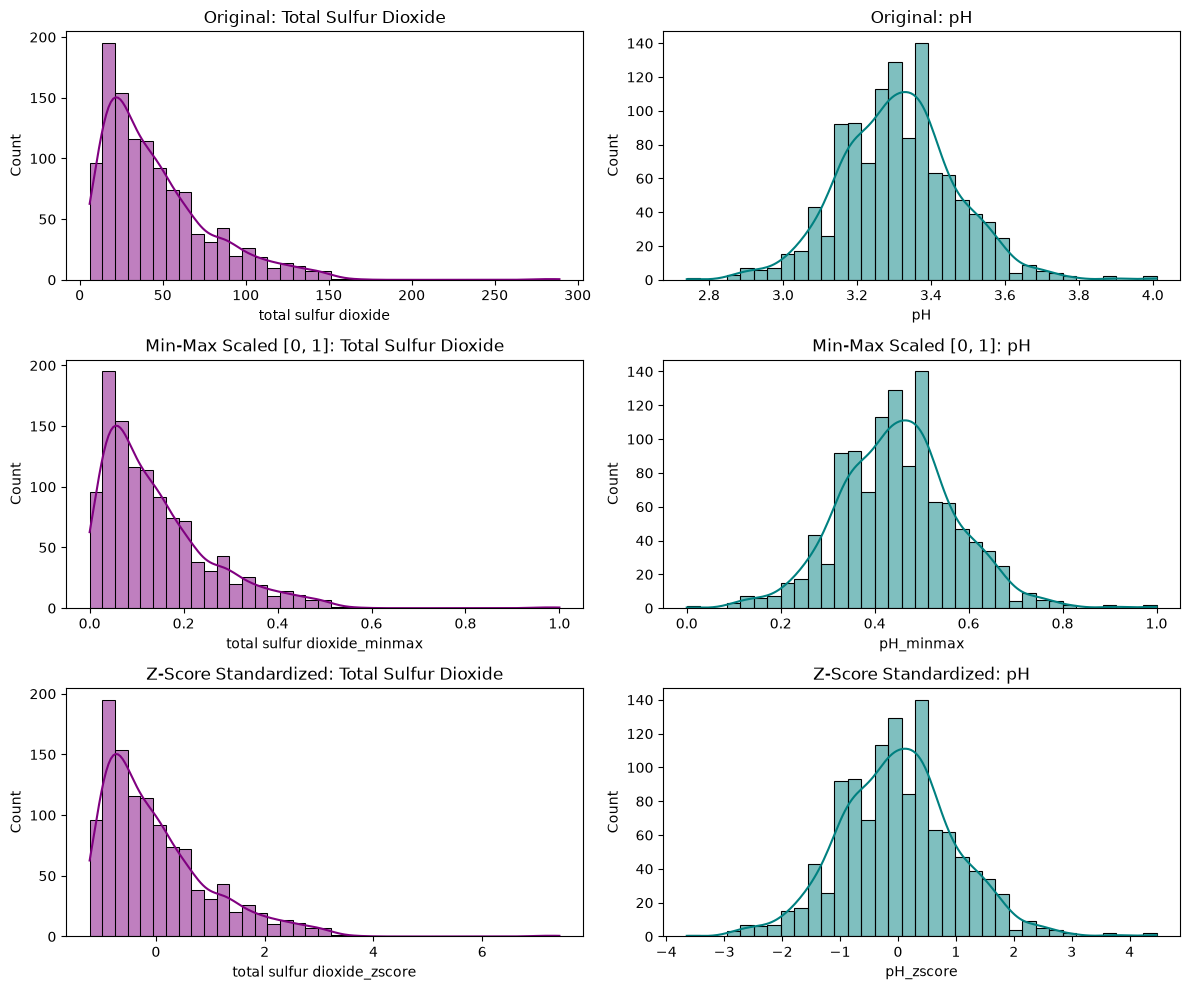

In [19]:


min_max_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(
    min_max_scaler.fit_transform(df[features]),
    columns=[f'{c}_minmax' for c in features],
)

standard_scaler = StandardScaler()
df_standard = pd.DataFrame(
    standard_scaler.fit_transform(df[features]),
    columns=[f'{c}_zscore' for c in features],
)

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

sns.histplot(
    df['total sulfur dioxide'], kde=True, ax=axes[0, 0], color='purple'
)
axes[0, 0].set_title('Original: Total Sulfur Dioxide')

sns.histplot(df['pH'], kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Original: pH')

sns.histplot(
    df_minmax['total sulfur dioxide_minmax'],
    kde=True,
    ax=axes[1, 0],
    color='purple',
)
axes[1, 0].set_title('Min-Max Scaled [0, 1]: Total Sulfur Dioxide')

sns.histplot(
    df_minmax['pH_minmax'], kde=True, ax=axes[1, 1], color='teal'
)
axes[1, 1].set_title('Min-Max Scaled [0, 1]: pH')

sns.histplot(
    df_standard['total sulfur dioxide_zscore'],
    kde=True,
    ax=axes[2, 0],
    color='purple',
)
axes[2, 0].set_title('Z-Score Standardized: Total Sulfur Dioxide')

sns.histplot(
    df_standard['pH_zscore'], kde=True, ax=axes[2, 1], color='teal'
)
axes[2, 1].set_title('Z-Score Standardized: pH')

plt.tight_layout()
plt.show()

**Min-Max Normalization**
* Best for algorithms that need inputs strictly bounded between 0 and 1, such as Neural Networks and distance-based models like K-Nearest Neighbors (KNN).* Works well when data has fixed upper and lower limits without extreme outliers.
* In our run, it forced all numbers from both features into the range $[0.0, 1.0]$.

**Z-Score Standardization**

* Best for algorithms that assume data follows a normal bell curve, such as Principal Component Analysis (PCA), Support Vector Machines (SVM), and Linear/Logistic Regression.
* Handles extreme values better than Min-Max because it does not squash the rest of the values into a tiny range.
* In our run, it centered both distributions around a mean of 0.0 with a standard deviation of 1.0.

### 2.2 B2. Feature Creation & Discretization

In [20]:
# Feature creation
df['bound_sulfur_dioxide'] = df['total sulfur dioxide'] - df['free sulfur dioxide']

df[['total sulfur dioxide', 'free sulfur dioxide', 'bound_sulfur_dioxide']].head()

,total sulfur dioxide,free sulfur dioxide,bound_sulfur_dioxide
0,34.0,11.0,23.0
1,67.0,25.0,42.0
2,54.0,15.0,39.0
3,60.0,17.0,43.0
4,34.0,11.0,23.0


In [21]:
# discretization
df['alcohol_eq_width'], width_bins = pd.cut(
    df['alcohol'], 
    bins=3, 
    labels=['Low', 'Medium', 'High'], 
    retbins=True
)

df['alcohol_eq_freq'], freq_bins = pd.qcut(
    df['alcohol'], 
    q=3, 
    labels=['Low', 'Medium', 'High'], 
    retbins=True
)

In [22]:
print("\nBin Boundaries")
print("Equal-Width Cutoffs:", np.round(width_bins, 2))
print("Equal-Frequency Cutoffs:", np.round(freq_bins, 2))

# Print Row Counts
print("\nBin Row Counts")
print("Equal-Width Counts:")
print(df['alcohol_eq_width'].value_counts().sort_index())
print("\nEqual-Frequency Counts:")
print(df['alcohol_eq_freq'].value_counts().sort_index())

ohe_df = pd.get_dummies(df['alcohol_eq_freq'], prefix='alcohol', dtype=int)

print("\nOne-Hot Encoded Features")
display(ohe_df.head())


Bin Boundaries
Equal-Width Cutoffs: [ 8.39 10.57 12.73 14.9 ]
Equal-Frequency Cutoffs: [ 8.4  9.7 10.8 14.9]

Bin Row Counts
Equal-Width Counts:
alcohol_eq_width
Low       699
Medium    405
High       39
Name: count, dtype: int64

Equal-Frequency Counts:
alcohol_eq_freq
Low       390
Medium    377
High      376
Name: count, dtype: int64

One-Hot Encoded Features


,alcohol_Low,alcohol_Medium,alcohol_High
0,1,0,0
1,0,1,0
2,0,1,0
3,0,1,0
4,1,0,0


 **Impact on Machine Learning Models**

 * Feature Creation: Adding domain-specific features like bound_sulfur_dioxide provides algorithms with explicit chemical signals directly linked to wine stability, saving tree models or linear regressors from having to learn complex subtraction patterns on their own.
 * Equal-Width Binning: Creates easy-to-understand intervals, but when data is right-skewed (like wine alcohol levels), it leaves high-end bins with very few samples ($39$ vs $699$). This imbalance can cause models to underperform when predicting high-alcohol categories.
 * Equal-Frequency Binning: Solves class imbalance by ensuring every bin gets roughly $33\%$ of the dataset (~$380$ samples). This makes it much better for training classifiers, though interval widths vary ($1.3$ for Low vs. $4.1$ for High).
 * One-Hot Encoding: Allows linear models, logistic regression, and neural networks to process non-numeric categorical data without mistakenly assuming an arbitrary math relationship (e.g., treating 'High' as 3X greater than 'Low'). However, it increases dataset dimensionality.

### 3 Additional Analytical Tasks

#### 3.1 D1. Measures of Similarity and Dissimilarity 

**Goal:** see how similar or different two wines are using a few metrics, then compare what each number actually says.

To make the comparison meaningful, two wines at opposite ends of the quality scale are picked: the lowest-rated wine (quality 3) and the highest-rated wine (quality 8). All 11 original chemical columns are used (`quality`, `Id`, and the B2 engineered columns are left out, since those would just duplicate information already in the base features).

In [23]:
base_cols = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
             'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
             'density', 'pH', 'sulphates', 'alcohol']

low_q_idx = df['quality'].idxmin()
high_q_idx = df['quality'].idxmax()

wine_a = df.loc[low_q_idx, base_cols].values.astype(float)
wine_b = df.loc[high_q_idx, base_cols].values.astype(float)

print(f"Wine A -> Id {df.loc[low_q_idx, 'Id']}, quality {df.loc[low_q_idx, 'quality']}")
print(f"Wine B -> Id {df.loc[high_q_idx, 'Id']}, quality {df.loc[high_q_idx, 'quality']}\n")

vector_table = pd.DataFrame({'Wine A (low quality)': wine_a, 'Wine B (high quality)': wine_b}, index=base_cols)
print(vector_table)

Wine A -> Id 459, quality 3
Wine B -> Id 267, quality 8

                      Wine A (low quality)  Wine B (high quality)
fixed acidity                      11.6000                 7.9000
volatile acidity                    0.5800                 0.3500
citric acid                         0.6600                 0.4600
residual sugar                      2.2000                 3.6000
chlorides                           0.0740                 0.0780
free sulfur dioxide                10.0000                15.0000
total sulfur dioxide               47.0000                37.0000
density                             1.0008                 0.9973
pH                                  3.2500                 3.3500
sulphates                           0.5700                 0.8600
alcohol                             9.0000                12.8000


In [24]:
euclidean_dist = np.sqrt(np.sum((wine_a - wine_b) ** 2))
print(f"Euclidean distance between Wine A and Wine B: {euclidean_dist:.4f}")

Euclidean distance between Wine A and Wine B: 12.4610


In [25]:
set_a = {col for col, val, med in zip(base_cols, wine_a, df[base_cols].median()) if val > med}
set_b = {col for col, val, med in zip(base_cols, wine_b, df[base_cols].median()) if val > med}

jaccard = len(set_a & set_b) / len(set_a | set_b)

print("Wine A above-median traits:", set_a)
print("Wine B above-median traits:", set_b)
print(f"\nJaccard similarity: {jaccard:.4f}")

Wine A above-median traits: {'total sulfur dioxide', 'volatile acidity', 'fixed acidity', 'citric acid', 'density'}
Wine B above-median traits: {'pH', 'free sulfur dioxide', 'sulphates', 'residual sugar', 'alcohol', 'citric acid', 'density'}

Jaccard similarity: 0.2000


In [26]:
cosine_sim = np.dot(wine_a, wine_b) / (np.linalg.norm(wine_a) * np.linalg.norm(wine_b))
pearson_corr = np.corrcoef(wine_a, wine_b)[0, 1]

print(f"Cosine similarity: {cosine_sim:.4f}")
print(f"Pearson correlation: {pearson_corr:.4f}")

Cosine similarity: 0.9770
Pearson correlation: 0.9713


In [27]:
metrics_table = pd.DataFrame({
    'Metric': ['Euclidean Distance', 'Jaccard Similarity', 'Cosine Similarity', 'Pearson Correlation'],
    'Value': [round(euclidean_dist, 4), round(jaccard, 4), round(cosine_sim, 4), round(pearson_corr, 4)],
    'Possible Range': ['[0, inf)', '[0, 1]', '[-1, 1]', '[-1, 1]']
})
print(metrics_table.to_string(index=False))

             Metric   Value Possible Range
 Euclidean Distance 12.4610       [0, inf)
 Jaccard Similarity  0.2000         [0, 1]
  Cosine Similarity  0.9770        [-1, 1]
Pearson Correlation  0.9713        [-1, 1]


**What each metric measures**
* Euclidean distance – straight-line distance across all 11 dimensions; bigger-scale features (like total sulfur dioxide, up to ~289) dominate the number.
* Jaccard similarity – overlap between the *sets* of traits each wine is above-median in; ignores magnitude, only cares which traits are shared.
* Cosine similarity – angle between the two vectors, so it captures the *pattern* of the values, not their scale.
* Pearson correlation – how linearly the two wines' values move together.

**Why the results differ**

Euclidean distance came out at 12.46, which looks "far apart", but that's mostly driven by the few large-scale features (fixed acidity, total sulfur dioxide) rather than every feature disagreeing. Jaccard is the lowest at 0.20 — Wine A and Wine B only share 2 out of 10 above-median traits (citric acid, density), so purely by feature overlap they look quite different. Cosine (0.977) and Pearson (0.971) are both close to 1 even though the two wines sit on opposite ends of the quality scale — their feature values still rise and fall together in a similar overall pattern, so direction/shape-based metrics stay high while a scale-sensitive metric like Euclidean does not. Basically: Euclidean and Jaccard react to actual differences in values/traits, cosine and Pearson mostly react to shape and can stay high even for very differently-rated wines.

### 3.2 D2. Dimensionality Reduction (PCA)

**Goal:** reduce the 11 numeric wine features to 2 dimensions with PCA, built manually using NumPy (no `sklearn.decomposition`), and check whether the 2D result still separates wines by quality.

Only the 11 original physicochemical columns are used (not `bound_sulfur_dioxide` from B2 — it's just `total sulfur dioxide` − `free sulfur dioxide`, so including it would add a perfectly correlated column to the covariance matrix).

In [48]:
X = df[base_cols].values
X_standardized = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized data shape:", X_standardized.shape)
print("Mean per column:", np.round(X_standardized.mean(axis=0), 2))
print("Std per column:", np.round(X_standardized.std(axis=0), 2))

Standardized data shape: (1143, 11)
Mean per column: [-0.  0.  0.  0.  0. -0.  0.  0. -0.  0. -0.]
Std per column: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [29]:
cov_matrix = np.cov(X_standardized, rowvar=False)
print("Covariance matrix shape:", cov_matrix.shape)

Covariance matrix shape: (11, 11)


In [ ]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

variance_pct = eigenvalues / eigenvalues.sum() * 100

pca_table = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Eigenvalue': np.round(eigenvalues, 3),
    'Variance Explained (%)': np.round(variance_pct, 2),
    'Cumulative (%)': np.round(np.cumsum(variance_pct), 2)
})
print(pca_table.to_string(index=False))

Component  Eigenvalue  Variance Explained (%)  Cumulative (%)
      PC1       3.159                   28.69           28.69
      PC2       1.880                   17.08           45.77
      PC3       1.575                   14.31           60.07
      PC4       1.213                   11.01           71.09
      PC5       0.959                    8.71           79.80
      PC6       0.666                    6.05           85.85
      PC7       0.558                    5.07           90.92
      PC8       0.419                    3.81           94.73
      PC9       0.345                    3.13           97.86
     PC10       0.177                    1.61           99.47
     PC11       0.059                    0.53          100.00


In [31]:
top2_eigenvectors = eigenvectors[:, :2]
X_pca = X_standardized @ top2_eigenvectors

print(f"Reduced from {X_standardized.shape[1]} dimensions to {X_pca.shape[1]}")
print(f"Top 2 components keep {variance_pct[:2].sum():.2f}% of total variance\n")
print("First 5 rows of projected data:")
print(pd.DataFrame(X_pca[:5], columns=['PC1', 'PC2']))

Reduced from 11 dimensions to 2
Top 2 components keep 45.77% of total variance

First 5 rows of projected data:
        PC1       PC2
0  1.561545 -0.444892
1  0.760892 -1.915058
2  0.708085 -0.914423
3 -2.308166  0.224448
4  1.561545 -0.444892


**What each step means**
* Standardizing puts all 11 features on the same scale (mean 0, std 1), so no feature dominates just because of its units.
* The covariance matrix (11x11) captures how every pair of features moves together.
* Eigenvectors of that matrix point toward directions of maximum spread; eigenvalues say how much variance each direction captures.
* Sorting eigenvalues largest to smallest and keeping the top 2 keeps the two directions that preserve the most information.

**What the numbers say**

PC1 explains 28.69% of the variance and PC2 adds 17.08% more, so the top 2 components keep 45.77% of the total spread out of 11 dimensions. That's a big compression but it does lose more than half the original variance, so this PCA is more useful for visualizing the data than as a lossless summary.

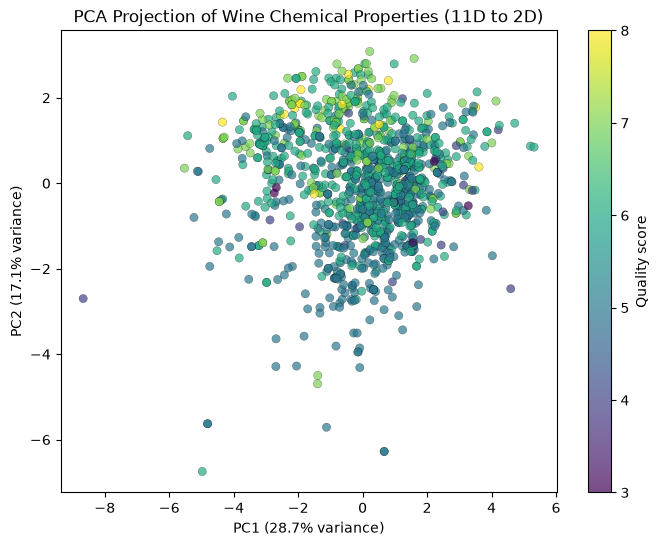

In [32]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['quality'], cmap='viridis', alpha=0.7, edgecolor='k', linewidth=0.2)
plt.colorbar(sc, label='Quality score')
plt.xlabel(f'PC1 ({variance_pct[0]:.1f}% variance)')
plt.ylabel(f'PC2 ({variance_pct[1]:.1f}% variance)')
plt.title('PCA Projection of Wine Chemical Properties (11D to 2D)')
plt.show()

**What the plot shows**

Higher-quality wines (yellow/green) lean toward higher PC1 values, lower-quality wines (purple) sit more toward negative PC1 — there's a visible gradient, not a hard separation. The overlap between quality groups makes sense, since PC1+PC2 only hold 45.77% of the original information and wine quality itself is a fairly noisy, subjective score.

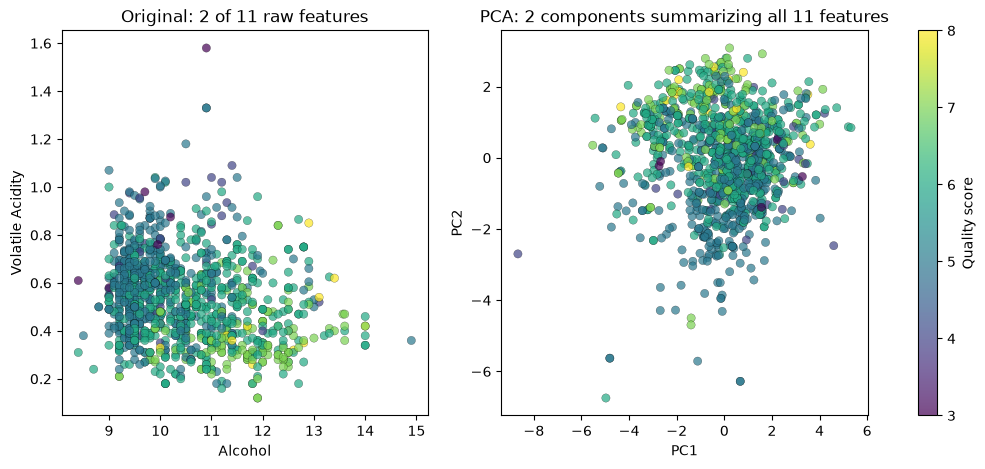

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sc1 = axes[0].scatter(df['alcohol'], df['volatile acidity'], c=df['quality'], cmap='viridis', alpha=0.7, edgecolor='k', linewidth=0.2)
axes[0].set_xlabel('Alcohol')
axes[0].set_ylabel('Volatile Acidity')
axes[0].set_title('Original: 2 of 11 raw features')

sc2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=df['quality'], cmap='viridis', alpha=0.7, edgecolor='k', linewidth=0.2)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('PCA: 2 components summarizing all 11 features')

fig.colorbar(sc2, ax=axes.ravel().tolist(), label='Quality score')
plt.show()

**Original vs. reduced structure**

The left plot uses just 2 of the 11 raw features (alcohol vs. volatile acidity) and already hints at a quality gradient along the alcohol axis. The right plot (PC1 vs PC2) is built from all 11 features compressed into 2 axes and shows a similar left-to-right quality gradient, slightly clearer, since PC1 is a weighted mix of several correlated features (mainly acidity, density and pH — the largest loadings) rather than a single column. So PCA didn't uncover a totally new pattern here, it mostly concentrated the separation that a couple of raw features already showed into fewer axes.

# Level C

### 4.1 C1. Advanced Sampling & Data Quality Analysis

Dataset: `student_exam_performance.csv`, 100,000 rows — meets the size requirement. `family_income` (5 levels) is used for **stratification**, since income is a known driver of academic outcomes. `age` (14–20, ~14k students each) is used as the **cluster identifier** — students of the same age are normally taught in the same grade/cohort, so sampling whole age groups mimics sampling whole classrooms instead of individual students one by one.

In [34]:
df_students = pd.read_csv('./datasets/student_exam_performance.csv')

print("INFORMATION OF DataSet\n")
df_students.info()

INFORMATION OF DataSet

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  str    
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   education_level             100000 non-null  str    
 4   school_type                 100000 non-null  str    
 5   family_income               100000 non-null  str    
 6   parent_education            93474 non-null   str    
 7   urban_rural                 100000 non-null  str    
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  str    
 13  st

In [35]:
df_students.head(10)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,...,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,...,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
5,STU_000006,18,Male,High School,Public,High,High School,Rural,67.68,NaN,...,Hard,27,96,65,55.27,6.12,67.90,C,Pass,Medium
6,STU_000007,18,Male,High School,Charter,Middle,NaN,Urban,78.84,3.00,...,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
7,STU_000008,20,Female,Undergraduate,Private,Lower-Middle,Bachelor,Suburban,90.79,3.63,...,Easy,7,94,91,88.08,10.00,97.61,A,Pass,High
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,...,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low
9,STU_000010,16,Female,Undergraduate,Public,Lower-Middle,Associate,Rural,61.33,2.72,...,Hard,4,87,34,73.78,8.49,39.05,F,Fail,Low


In [36]:
print("Shape:", df_students.shape)
print()
missing = df_students.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0])

Shape: (100000, 44)

Columns with missing values:
parent_education         6526
previous_gpa             7793
attendance_percentage    9863
notes_quality            8407
sleep_quality            6994
device_availability      2965
time_management_score    9613
dtype: int64


In [37]:
df_students[['student_id', 'age', 'family_income', 'school_type', 'exam_score']].head(10)

,student_id,age,family_income,school_type,exam_score
0,STU_000001,20,Middle,Public,90.40
1,STU_000002,17,Middle,Public,86.21
2,STU_000003,18,Middle,Public,76.11
3,STU_000004,20,Middle,Public,79.74
4,STU_000005,16,High,Private,50.66
5,STU_000006,18,High,Public,67.90
6,STU_000007,18,Middle,Charter,53.86
7,STU_000008,20,Lower-Middle,Private,97.61
8,STU_000009,15,Lower-Middle,Public,34.44
9,STU_000010,16,Lower-Middle,Public,39.05


In [38]:
print("family_income distribution (full dataset, %):")
print((df_students['family_income'].value_counts(normalize=True) * 100).round(2))

print("\nage distribution (full dataset, %):")
print((df_students['age'].value_counts(normalize=True).sort_index() * 100).round(2))

print("\nexam_score summary (full dataset):")
print(df_students['exam_score'].describe().round(3))

family_income distribution (full dataset, %):
family_income
Middle          30.11
Lower-Middle    25.07
Low             19.83
Upper-Middle    14.90
High            10.09
Name: proportion, dtype: float64

age distribution (full dataset, %):
age
14    14.23
15    14.32
16    14.03
17    14.41
18    14.39
19    14.31
20    14.31
Name: proportion, dtype: float64

exam_score summary (full dataset):
count    100000.000
mean         61.950
std          15.864
min           0.000
25%          51.240
50%          61.960
75%          72.730
max         100.000
Name: exam_score, dtype: float64


**Why these two variables**

`family_income` clearly matters for `exam_score` - mean scores rise from ~59.1 (Low) up to ~65.5 (High), a real ~6.4-point gap - so stratifying by it should help preserve the score distribution. `age` barely matters at all - group means sit in a tight 61.7–62.1 band regardless of age - so it isn't chosen because it predicts the outcome, only because it's a natural, pre-existing grouping (like a grade/cohort) that could realistically be sampled by cluster in the real world.

One helper function is reused for all three samples below so the stats code isn't repeated three times.

In [39]:
def describe_sample(sample, label):
    s = sample['exam_score']
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return {
        'Sample': label,
        'N': len(s),
        'Mean': round(s.mean(), 3),
        'Median': round(s.median(), 3),
        'Variance': round(s.var(), 3),
        'IQR': round(q3 - q1, 3)
    }

**(a) Simple Random Sample (10%)**

In [40]:
srs = df_students.sample(frac=0.10, random_state=42)
print("Simple random sample size:", len(srs), f"({len(srs)/len(df_students)*100:.1f}% of full data)")

Simple random sample size: 10000 (10.0% of full data)


**(b) Stratified Sample (10% drawn from each income group)**

In [41]:
strat = df_students.groupby('family_income', group_keys=False)[df_students.columns].apply(
    lambda x: x.sample(frac=0.10, random_state=42)
)
print("Stratified sample size:", len(strat), f"({len(strat)/len(df_students)*100:.1f}% of full data)\n")
print("family_income distribution inside stratified sample (%):")
print((strat['family_income'].value_counts(normalize=True) * 100).round(2))

Stratified sample size: 10000 (10.0% of full data)

family_income distribution inside stratified sample (%):
family_income
Middle          30.11
Lower-Middle    25.07
Low             19.83
Upper-Middle    14.90
High            10.09
Name: proportion, dtype: float64


**(c) Cluster Sample**

Justification: instead of drawing individual students, 3 of the 7 age-cohorts are picked at random and *every* student in those cohorts is kept - the same logic as surveying a few whole classrooms instead of scattered individuals. Because whole cohorts are kept, the resulting sample is much bigger than 10% (each cohort is ~14% of the data).

In [42]:
np.random.seed(42)
all_ages = sorted(df_students['age'].unique())
selected_ages = np.random.choice(all_ages, size=3, replace=False)
cluster = df_students[df_students['age'].isin(selected_ages)]

print("Age-clusters selected (3 of 7):", sorted(selected_ages.tolist()))
print("Cluster sample size:", len(cluster), f"({len(cluster)/len(df_students)*100:.1f}% of full data)")

Age-clusters selected (3 of 7): [14, 15, 19]
Cluster sample size: 42863 (42.9% of full data)


**Descriptive statistics: full dataset vs. the three samples**

In [43]:
comparison = pd.DataFrame([
    describe_sample(df_students, 'Full Dataset (100%)'),
    describe_sample(srs, 'Simple Random (10%)'),
    describe_sample(strat, 'Stratified (10%/group)'),
    describe_sample(cluster, 'Cluster (3/7 age groups)')
])
print(comparison.to_string(index=False))

                  Sample      N   Mean  Median  Variance    IQR
     Full Dataset (100%) 100000 61.950  61.960   251.655 21.490
     Simple Random (10%)  10000 62.092  61.955   253.774 21.713
  Stratified (10%/group)  10000 61.964  62.060   250.766 21.632
Cluster (3/7 age groups)  42863 62.077  62.110   251.436 21.570


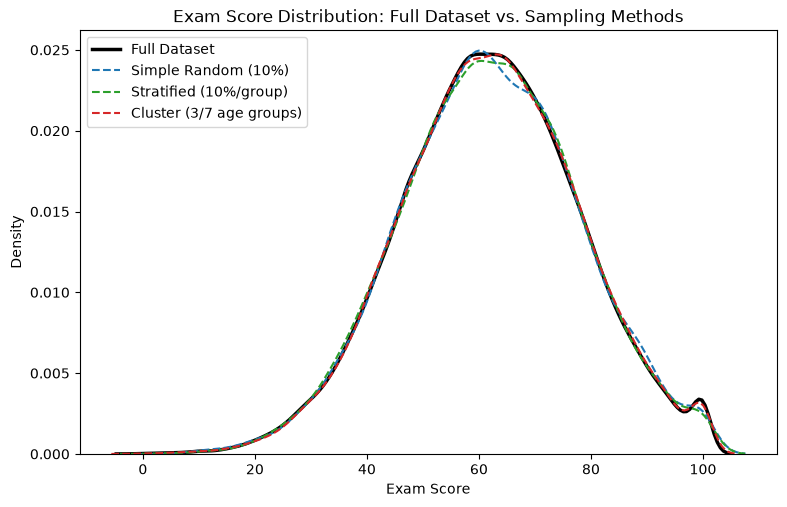

In [44]:
plt.figure(figsize=(9, 5.5))
sns.kdeplot(df_students['exam_score'], label='Full Dataset', color='black', linewidth=2.5)
sns.kdeplot(srs['exam_score'], label='Simple Random (10%)', color='tab:blue', linestyle='--')
sns.kdeplot(strat['exam_score'], label='Stratified (10%/group)', color='tab:green', linestyle='--')
sns.kdeplot(cluster['exam_score'], label='Cluster (3/7 age groups)', color='tab:red', linestyle='--')
plt.title('Exam Score Distribution: Full Dataset vs. Sampling Methods')
plt.xlabel('Exam Score')
plt.ylabel('Density')
plt.legend()
plt.show()

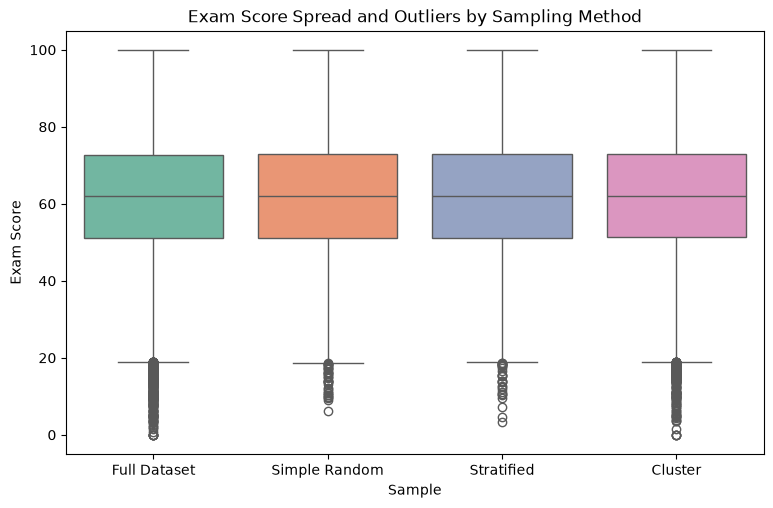

In [45]:
plot_data = pd.concat([
    df_students[['exam_score']].assign(Sample='Full Dataset'),
    srs[['exam_score']].assign(Sample='Simple Random'),
    strat[['exam_score']].assign(Sample='Stratified'),
    cluster[['exam_score']].assign(Sample='Cluster'),
])

plt.figure(figsize=(9, 5.5))
sns.boxplot(data=plot_data, x='Sample', y='exam_score', hue='Sample', palette='Set2', legend=False)
plt.title('Exam Score Spread and Outliers by Sampling Method')
plt.ylabel('Exam Score')
plt.show()

**Outlier detection (IQR rule, 1.5x) across the four groups**

In [46]:
def count_outliers(sample):
    s = sample['exam_score']
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = s[(s < lower) | (s > upper)]
    return len(outliers), len(outliers) / len(s) * 100

outlier_table = pd.DataFrame([
    {'Sample': name, 'N': len(sample), 'Outliers': count_outliers(sample)[0], 'Outlier %': round(count_outliers(sample)[1], 3)}
    for name, sample in [('Full Dataset', df_students), ('Simple Random', srs), ('Stratified', strat), ('Cluster', cluster)]
])
print(outlier_table.to_string(index=False))

       Sample      N  Outliers  Outlier %
 Full Dataset 100000       373      0.373
Simple Random  10000        36      0.360
   Stratified  10000        30      0.300
      Cluster  42863       162      0.378


               Full Dataset  Simple Random  Stratified  Cluster
family_income                                                  
Low                   19.83          19.99       19.83    19.58
Lower-Middle          25.07          25.12       25.07    25.18
Middle                30.11          29.94       30.11    30.39
Upper-Middle          14.90          14.44       14.90    14.81
High                  10.09          10.51       10.09    10.03


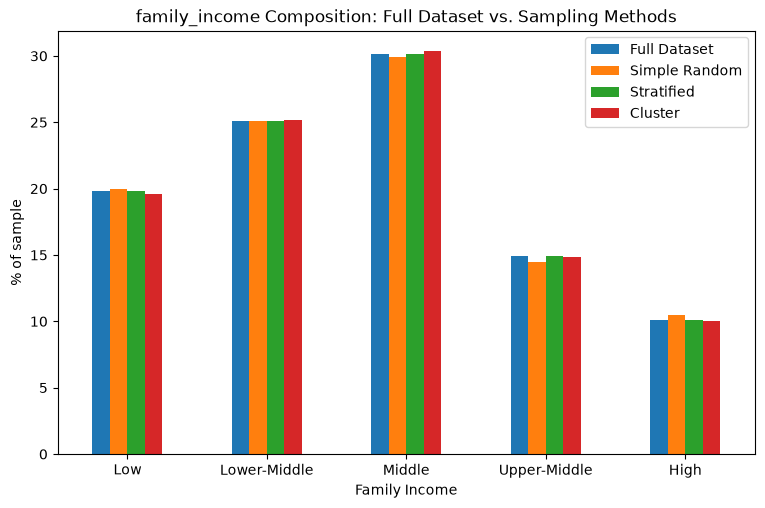

In [47]:
income_order = ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High']
props = pd.DataFrame({
    'Full Dataset': df_students['family_income'].value_counts(normalize=True),
    'Simple Random': srs['family_income'].value_counts(normalize=True),
    'Stratified': strat['family_income'].value_counts(normalize=True),
    'Cluster': cluster['family_income'].value_counts(normalize=True),
}).reindex(income_order) * 100

print(props.round(2))

props.plot(kind='bar', figsize=(9, 5.5))
plt.title('family_income Composition: Full Dataset vs. Sampling Methods')
plt.ylabel('% of sample')
plt.xlabel('Family Income')
plt.xticks(rotation=0)
plt.show()

**Analytical report**

*Which method preserved the distribution best?* Stratified sampling was the closest match overall - mean 61.964 vs. the full dataset's 61.950, and it reproduces the `family_income` proportions exactly by construction (e.g. Middle 30.11% in both). Simple random sampling was a close second (mean 62.092, IQR 21.713 vs. 21.490) - with 10,000 rows even plain random draws land near the population values. Cluster sampling landed close too (mean 62.077), but only because `age` barely affects `exam_score` - with a cluster variable that actually mattered, this method would likely have drifted further from the true distribution.

*Impact on outlier detection.* The full dataset has 373 IQR-outliers (0.373%). Both 10%-sized samples caught noticeably fewer relative to their size - Simple Random found 36 (0.360%) and Stratified only 30 (0.300%). The Cluster sample, despite not being designed to hit a target size, kept 42,863 rows and picked up 162 outliers (0.378%) - nearly matching the full dataset's rate simply because it kept far more data. This shows a real trade-off: shrinking a sample for convenience shrinks your chances of catching rare/extreme cases along with it.

*Recommendations for real-world projects.*
* Stratify whenever a variable is known to affect the outcome (like income here) - it protects proportional representation directly.
* Plain random sampling is a fine default with no obvious grouping variable, but don't expect it to catch rare cases reliably at low sampling fractions.
* Cluster sampling is worth it mainly for logistics/cost (surveying whole groups is cheaper than reaching scattered individuals) - its accuracy depends entirely on how similar the clusters are to each other; age worked here only because it happens not to drive exam performance.
* If detecting rare/extreme cases matters for the project, keep the sample size large regardless of method - all three samples here undercounted outliers relative to the full dataset, and 10%-sized samples were the worst affected.